# 06 - Risk Scoring and Retention Insights

Scores every customer with a churn probability and groups them into risk bands for the Power BI dashboard.

To avoid scoring customers with a model that has already seen them, probabilities come from 5-fold cross-validation (each customer is scored by a model trained on the other folds).

Output: `Data/Processed/customer_risk_scores.csv`

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict

sns.set_theme(style="whitegrid", palette="deep")

clean = pd.read_csv("../Data/Processed/telco_churn_clean.csv")
feats = pd.read_csv("../Data/Processed/churn_features.csv")
saved = joblib.load("../models/churn_model.joblib")
THRESHOLD = saved["threshold"]
print(saved["model_name"], "| threshold", THRESHOLD)

Logistic Regression | threshold 0.33


In [2]:
X = feats[saved["features"]]
y = feats["churn_value"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba = cross_val_predict(clone(saved["pipeline"]), X, y, cv=cv, method="predict_proba")[:, 1]

scores = clean[["customer_id", "city", "latitude", "longitude", "gender", "senior_citizen", "tenure_months",
                "tenure_group", "contract", "internet_service", "payment_method", "monthly_charges",
                "total_charges", "cltv", "churn_value", "churn_label", "churn_reason"]].copy()
scores["churn_probability"] = proba.round(4)
scores["predicted_churn"] = (proba >= THRESHOLD).astype(int)
scores.shape

(7043, 19)

## Risk bands

- **Low:** below the decision threshold
- **Medium:** from the threshold up to 0.60
- **High:** 0.60 and above

In [3]:
scores["risk_band"] = pd.cut(scores["churn_probability"], bins=[-0.01, THRESHOLD, 0.60, 1.0],
                             labels=["Low", "Medium", "High"]).astype(str)

band = scores.groupby("risk_band").agg(
    customers=("customer_id", "count"),
    actual_churn_rate=("churn_value", "mean"),
    avg_probability=("churn_probability", "mean"),
    monthly_revenue=("monthly_charges", "sum"),
).reindex(["Low", "Medium", "High"])
band["actual_churn_rate"] = (band["actual_churn_rate"] * 100).round(1)
band.round(2)

,customers,actual_churn_rate,avg_probability,monthly_revenue
risk_band,,,,
Low,3334,4.9,0.11,189929.65
Medium,1322,25.0,0.47,82632.20
High,2387,57.6,0.78,183554.75


The bands behave as they should: the actual churn rate rises sharply from Low to High, so the score ranks customers well.

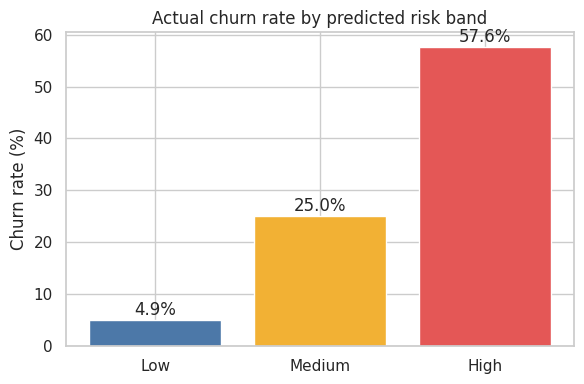

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
colors = ["#4C78A8", "#F2B134", "#E45756"]
ax.bar(band.index, band["actual_churn_rate"], color=colors)
for i, v in enumerate(band["actual_churn_rate"]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_title("Actual churn rate by predicted risk band")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../images/15_risk_band_churn_rate.png", dpi=130, bbox_inches="tight")

## Customers who are still active

In [5]:
active = scores[scores["churn_value"] == 0]
high = active[active["risk_band"] == "High"]
med = active[active["risk_band"] == "Medium"]

print(f"Active customers          : {len(active):,}")
print(f"High risk (still active)  : {len(high):,}  -> monthly revenue ${high['monthly_charges'].sum():,.0f}")
print(f"Medium risk (still active): {len(med):,}  -> monthly revenue ${med['monthly_charges'].sum():,.0f}")
print(f"High-risk lifetime value  : ${high['cltv'].sum():,.0f}")

Active customers          : 5,174
High risk (still active)  : 1,013  -> monthly revenue $76,139
Medium risk (still active): 991  -> monthly revenue $61,547
High-risk lifetime value  : $4,178,886


In [6]:
profile = high.groupby(["contract", "internet_service"]).agg(
    customers=("customer_id", "count"),
    monthly_revenue=("monthly_charges", "sum"),
    avg_probability=("churn_probability", "mean"),
).sort_values("monthly_revenue", ascending=False).round(2)
profile.head(8)

customers  monthly_revenue  avg_probability
contract       internet_service                                             
Month-to-month Fiber optic             662         57818.15             0.77
               DSL                     308         15158.55             0.71
One year       Fiber optic              26          2560.25             0.65
               DSL                       6           362.85             0.65
Month-to-month No                       11           239.15             0.63

In [7]:
# 25 highest-value active customers most likely to leave: the first call list
call_list = (high.sort_values(["churn_probability", "cltv"], ascending=False)
                 [["customer_id", "city", "contract", "internet_service", "payment_method",
                   "tenure_months", "monthly_charges", "cltv", "churn_probability"]]
                 .head(25))
call_list.reset_index(drop=True)

,customer_id,city,contract,internet_service,payment_method,tenure_months,monthly_charges,cltv,churn_probability
0,3489-HHPFY,Amboy,Month-to-month,Fiber optic,Electronic check,2,84.05,2115,0.9454
1,6630-UJZMY,Palo Alto,Month-to-month,Fiber optic,Electronic check,4,83.25,5251,0.9451
2,7398-SKNQZ,Downey,Month-to-month,Fiber optic,Electronic check,3,94.90,2330,0.9443
3,4927-WWOOZ,Pacific Grove,Month-to-month,Fiber optic,Electronic check,2,91.45,4889,0.9428
4,0187-QSXOE,Fresno,Month-to-month,Fiber optic,Electronic check,7,89.00,5711,0.9404
5,2077-MPJQO,Menlo Park,Month-to-month,Fiber optic,Electronic check,7,75.40,3533,0.9345
6,5150-ITWWB,Hamilton City,Month-to-month,Fiber optic,Electronic check,3,94.85,4496,0.9300
7,2545-EBUPK,Los Angeles,Month-to-month,Fiber optic,Electronic check,2,84.05,5039,0.9295
8,9334-GWGOW,Mc Kittrick,Month-to-month,Fiber optic,Electronic check,7,74.85,2259,0.9290
9,8622-ZLFKO,Fresno,Month-to-month,Fiber optic,Electronic check,6,90.75,4297,0.9269


## Suggested actions by segment

| Segment | Pattern in the data | Action |
|---|---|---|
| New month-to-month customers | about 47% churn in year one | onboarding check-ins, first-year discount for moving to a 12-month plan |
| Fiber customers without security/support | churn above 50% | free trial of Online Security / Tech Support |
| Electronic-check payers | 45% churn vs about 16% on autopay | small credit for switching to automatic payment |
| High-risk, high-value accounts | top of the call list | proactive outreach by an account team |

In [8]:
out = scores.copy()
out.to_csv("../Data/Processed/customer_risk_scores.csv", index=False)
print(out.shape)
out["risk_band"].value_counts()

(7043, 20)


risk_band
Low       3334
High      2387
Medium    1322